<a href="https://colab.research.google.com/github/rach-horsman/skills-introduction-to-github/blob/main/test.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Epoch 1/500
2/2 [==============================] - 0s 7ms/step - loss: 0.0951
Epoch 2/500
2/2 [==============================] - 0s 6ms/step - loss: 0.0945
Epoch 3/500
2/2 [==============================] - 0s 6ms/step - loss: 0.0939
Epoch 4/500
2/2 [==============================] - 0s 6ms/step - loss: 0.0932
Epoch 5/500
2/2 [==============================] - 0s 6ms/step - loss: 0.0926
Epoch 6/500
2/2 [==============================] - 0s 6ms/step - loss: 0.0920
Epoch 7/500
2/2 [==============================] - 0s 6ms/step - loss: 0.0915
Epoch 8/500
2/2 [==============================] - 0s 6ms/step - loss: 0.0909
Epoch 9/500
2/2 [==============================] - 0s 9ms/step - loss: 0.0903
Epoch 10/500
2/2 [==============================] - 0s 6ms/step - loss: 0.0897
Epoch 11/500
2/2 [==============================] - 0s 7ms/step - loss: 0.0892
Epoch 12/500
2/2 [==============================] - 0s 8ms/step - loss: 0.0886
Epoch 13/500
2/2 [==============================] - 0s 6ms/st

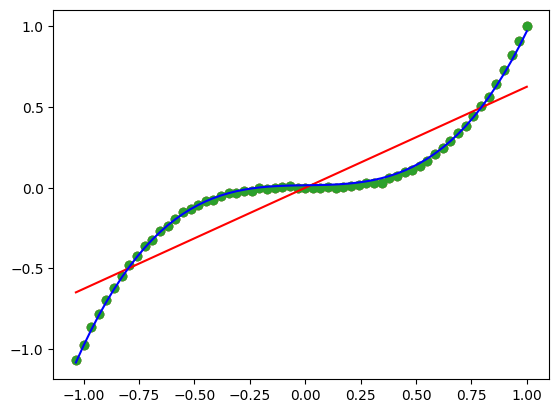

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from sklearn.preprocessing import PolynomialFeatures

def generate_data():
    X = np.arange(-30, 30, 1)
    y = 9*X**3 + 5*X**2 + np.random.randn(60)*1000
    return X, y
trX, trY = generate_data()
trX = trX/max(trX)
trY = trY/max(trY)
#plot the data
fig, ax = plt.subplots()
ax.scatter(trX, trY)

n = 3
trX_expanded = np.expand_dims(trX, axis=1)
poly = PolynomialFeatures(n)
# returns: [1, x, x^2, x^3]
trX_expanded = poly.fit_transform(trX_expanded)

inp = Input((1))
out = Dense(1)(inp)
model_linear = Model(inputs=inp, outputs=out)
model_linear.compile(
optimizer=Adam(learning_rate=1e-3),
loss="mean_squared_error")

model_linear.fit(trX, trY, epochs=500)
ax.scatter(trX, trY)
ax.plot(trX, model_linear.predict(trX), color="red")

inp = Input((n+1))
#since one of the features is 1, we need an extra input
out = Dense(1)(inp)
model = Model(inputs=inp, outputs=out)
model.compile(optimizer=Adam(learning_rate=1e-3), loss="mean_squared_error")

model.fit(trX_expanded, trY, epochs=500)
ax.scatter(trX, trY)
ax.plot(trX, model.predict(trX_expanded), color="blue")

#print(model.predict([0.0]))